# 🌍 Data Visualization — Real-World Scenario Worksheet
### You are the analyst. Each task is a real situation with a *decision* at the end.

> **How this works**
> - Every task gives you a scenario, real-ish data, and a **question to answer with a chart**.
> - Don't just draw the chart — **pick the right one** and, in a comment, say what it tells you.
> - Fill in the `# YOUR CODE HERE` sections. Run each cell to check your output.
> - 🏆 Each task ends with a **"So what?"** — one sentence stating the insight, like a real analyst would tell their boss.


## ⚙️ Setup — Run This First

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
%matplotlib inline
sns.set_style('whitegrid')

---
## ☕ Task 1 — The Coffee Shop Owner

**Scenario:** You run a small coffee shop. You want to know **which days are busiest** so you can schedule more staff. Here are last week's cup sales.

**Your job:** Draw the chart that best compares days, and **highlight the two busiest days in a different colour** so the owner sees them instantly.

*(Hint: comparing categories → bar chart. To highlight, build a list of colours.)*

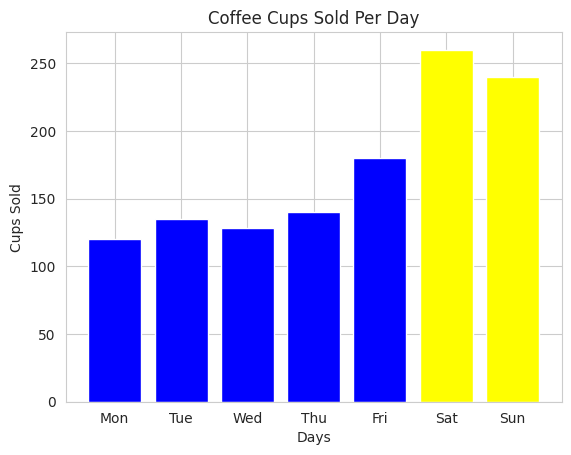

In [7]:
days  = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
cups  = [120, 135, 128, 140, 180, 260, 240]

# YOUR CODE HERE
# 1. Bar chart of cups per day
# 2. Colour Sat & Sun differently from weekdays
# A simple list of colors: 5 blues for weekdays, 2 oranges for the weekend
simple_colors = ['blue', 'blue', 'blue', 'blue', 'blue', 'yellow', 'yellow']
plt.bar(days, cups, color=simple_colors)

# 3. Add a title that states the insight, plus axis labels
plt.title("Coffee Cups Sold Per Day")
plt.xlabel("Days")
plt.ylabel("Cups Sold")
plt.show()

# 🏆 So what? (write one sentence as a comment)
# The busiest days are Saturday and Sunday, so the owner should schedule more staff on weekends.

---
## 🏃 Task 2 — The Fitness Tracker

**Scenario:** Your fitness app records daily steps. Your goal is **8,000 steps/day**. You want to see **which days you hit the goal and which you missed.**

**Your job:** Draw a line plot of steps over the week, then add a **horizontal goal line at 8,000** so misses are obvious at a glance.

*(Hint: change over time → line plot. Use `ax.axhline()` for the goal line.)*

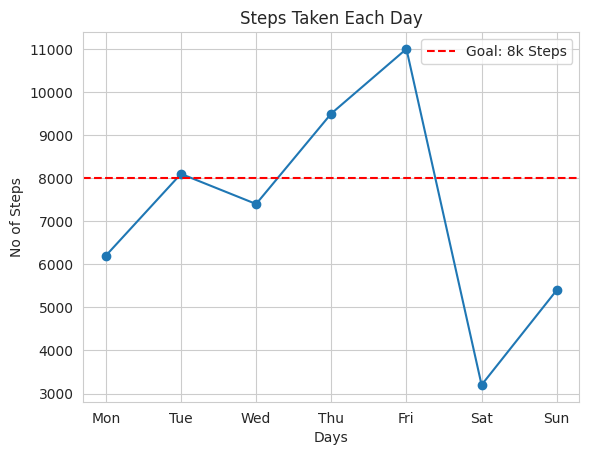

In [12]:
days  = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
steps = [6200, 8100, 7400, 9500, 11000, 3200, 5400]

# YOUR CODE HERE
# 1. Line plot of steps with markers
plt.plot(days, steps, marker='o')

# 2. Add a dashed red horizontal line at the 8000 goal (with a legend label)
plt.axhline(y=8000, color='red', linestyle='--', label='Goal: 8k Steps')

# 3. Title + axis labels
plt.title("Steps Taken Each Day")
plt.xlabel("Days")
plt.ylabel("No of Steps")
plt.legend()
plt.show()

# 🏆 So what? On which days did you MISS the goal?
# I missed the goal on Monday, Wednesday, Saturday, and Sunday.


---
## 📱 Task 3 — The Streaming Report (Pick the Right Chart!)

**Scenario:** A streaming service wants to show **how many hours were watched per genre**. A junior designer made a **pie chart** — but there are 6 genres with similar values, so it's unreadable.

**Your job:** Prove the point. Draw the **pie chart (the bad version)** AND a **sorted horizontal bar chart (the good version)** side by side. Then, in a comment, say which one answers *"which genre is #1?"* faster.

*(Hint: `plt.subplots(1, 2)`. Sort the data before the bar chart.)*

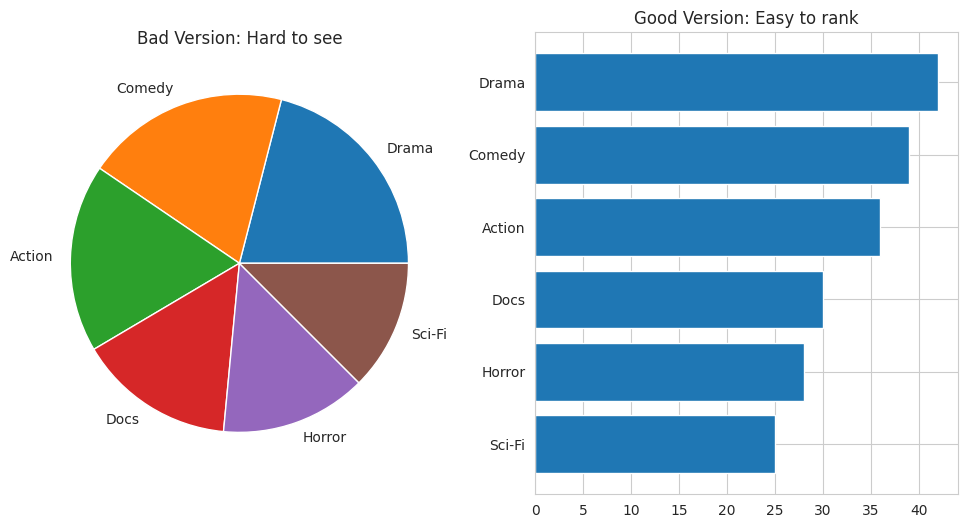

In [15]:
genres = ['Drama','Comedy','Action','Docs','Horror','Sci-Fi']
hours  = [42, 39, 36, 30, 28, 25]

# YOUR CODE HERE
# Put the data into a simple pandas table so it's easy to sort
df_movies = pd.DataFrame({'Genre': genres, 'Hours': hours})
df_sorted = df_movies.sort_values(by='Hours')

fig, axes = plt.subplots(1, 2, figsize=(12, 6)) #Matplotlib creates a grid with 1 row and 2 columns

# Left subplot: pie chart of the same data
axes[0].pie(hours, labels=genres)
axes[0].set_title("Bad Version: Hard to see")

# Right subplot: Sorted horizontal bar chart (using our sorted dataframe)
axes[1].barh(df_sorted['Genre'], df_sorted['Hours'])
axes[1].set_title("Good Version: Easy to rank")

plt.show()

# 🏆 So what? Which chart makes the ranking obvious, and why?
# The bar chart is obvious because human eyes compare straight lines much easier than pie slices.


---
## 🎓 Task 4 — Does Studying Actually Help? (Relationship)

**Scenario:** A school wants to know if **more study hours really lead to higher exam scores**, or if it's a myth.

**Your job:** Draw a **scatter plot** of study hours vs exam score. Then use Seaborn's `regplot` to add a **trend line** so the relationship is clear.

*(Hint: relationship between two numbers → scatter. `sns.regplot` adds the line for you.)*

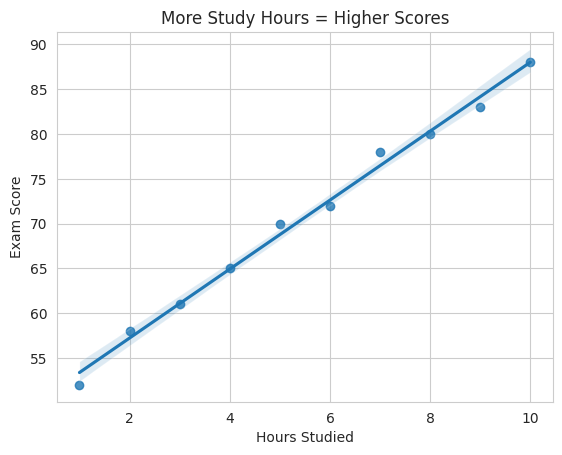

In [16]:
study_hours = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
exam_score  = [52, 58, 61, 65, 70, 72, 78, 80, 83, 88]

# YOUR CODE HERE
# 1. sns.regplot of study_hours (x) vs exam_score (y)
sns.regplot(x=study_hours, y=exam_score)

# 2. Title + axis labels
plt.title("More Study Hours = Higher Scores")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.show()

# 🏆 So what? Is the relationship positive, negative, or none?
# The relationship is positive (scores go up as study hours go up).


---
## 🍽️ Task 5 — The Restaurant Manager (Seaborn EDA)

**Scenario:** You manage a restaurant and want to know **when customers tip best**, so you can schedule your best servers then. Use the built-in `tips` dataset.

**Your job:** Build a **heatmap of average tip by day and time (Lunch/Dinner)**. The brightest cell is your money slot.

*(Hint: `pivot_table` to get day × time → tip, then `sns.heatmap(..., annot=True)`.)*

/tmp/ipykernel_1556/440889471.py:6: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  tip_grid = tips.pivot_table(index='day', columns='time', values='tip', aggfunc='mean')


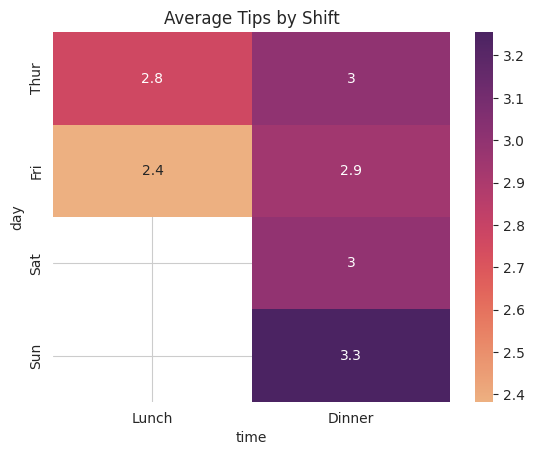

In [23]:
tips = sns.load_dataset('tips')

# YOUR CODE HERE
# 1. Make a pivot_table: index='day', columns='time', values='tip', aggfunc='mean'
# Think of this as making a simple spreadsheet grid.
tip_grid = tips.pivot_table(index='day', columns='time', values='tip', aggfunc='mean')

# 2. sns.heatmap of that table with annot=True and a colour map
sns.heatmap(tip_grid, annot=True, cmap='flare')

# 3. Title
plt.title("Average Tips by Shift")
plt.show()

# 🏆 So what? Which day + time has the highest average tip?
# Sunday Dinner has the highest average tip.


---
## 📈 Task 6 — The Startup Pitch (Interactive Plotly)

**Scenario:** You're pitching investors and want an **interactive** chart they can hover over. Using the `gapminder` dataset, show **how life expectancy relates to income**, and let them **watch it change over the years.**

**Your job:** Build a Plotly **animated scatter plot**: `gdpPercap` (x, log scale) vs `lifeExp` (y), bubble size = population, colour = continent, animation frame = year.

*(Hint: `px.scatter(..., animation_frame='year', log_x=True, size='pop', color='continent')`.)*

In [41]:
gapminder = px.data.gapminder()

# YOUR CODE HERE — one px.scatter call with animation_frame='year'
# We just tell Plotly which column goes to which setting.
fig = px.scatter(
    gapminder,
    x='gdpPercap',
    y='lifeExp',
    animation_frame='year',
    animation_group='country',
    log_x=True,
    size='pop',
    color='continent',
    hover_name='country',

    size_max=80,                  # Makes the largest bubbles bigger and easier to see
    range_x=[100, 100000],        # Locks the X-axis so it doesn't shift every year
    range_y=[25, 90],             # Locks the Y-axis across all years
    width=1000,                   # Makes the canvas wider
    height=600,                   # Makes the canvas taller
    title='Life Expectency And Its Relationship To Income(Over the Years)'
)

fig.show()

# 🏆 So what? What overall trend do you see as the years play forward?
# Over the years, countries generally move up and to the right (getting richer and living longer).


---
## 🛒 Task 7 — CAPSTONE: The E-Commerce Dashboard (Your Judgment)

**Scenario:** You're the data analyst for an online store. The founder asks for a **one-glance dashboard** of last week's performance. Below is the data.

**Your job:** Build a **2×2 dashboard** (`plt.subplots(2, 2)`). *You* choose the 4 charts — but you must pick the **right chart for each question** and write *why* in a comment above each.

Answer these 4 questions, one per subplot:
1. How did **daily revenue trend** across the week?
2. How do **orders compare** across days?
3. Is there a **relationship between orders and revenue**?
4. What **share of revenue** came from each product category? *(few categories → pie is OK here)*


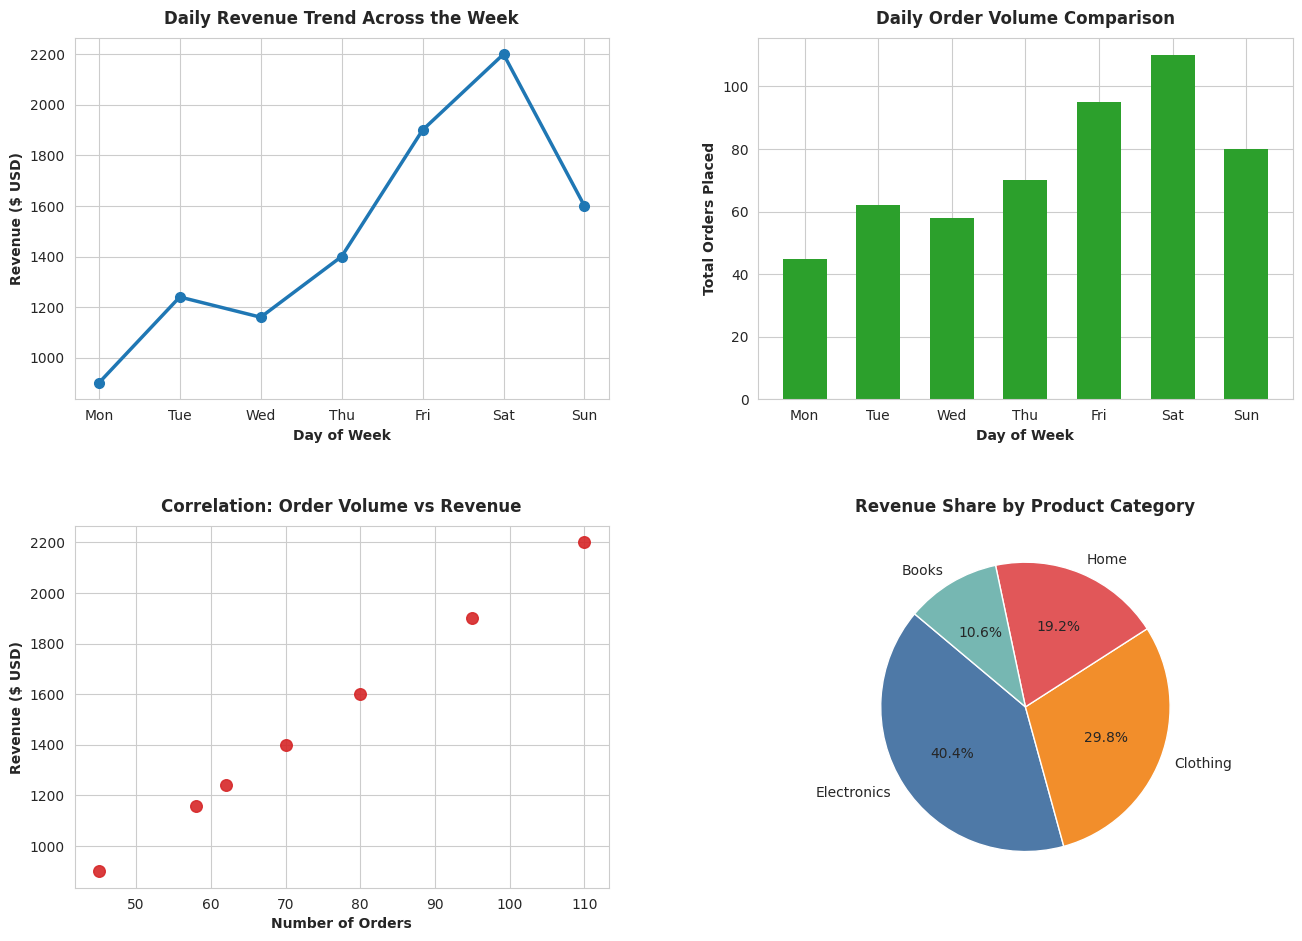

In [55]:
df = pd.DataFrame({
    'Day':      ['Mon','Tue','Wed','Thu','Fri','Sat','Sun'],
    'Orders':   [45,   62,   58,   70,   95,  110,   80 ],
    'Revenue':  [900, 1240, 1160, 1400, 1900, 2200, 1600],
})
cat_names  = ['Electronics','Clothing','Home','Books']
cat_revenue= [4200, 3100, 2000, 1100]


# Create a spacious 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# -------------------------------------------------------------
# (0,0) Chart type chosen: Line Plot | Why: Best for displaying continuous trends over time (days).
# -------------------------------------------------------------
axes[0, 0].plot(df['Day'], df['Revenue'], marker='o', markersize=7, color='#1f77b4', linewidth=2.5)
axes[0, 0].set_title('Daily Revenue Trend Across the Week', fontsize=12, fontweight='bold', pad=10)
axes[0, 0].set_xlabel('Day of Week', fontsize=10, fontweight='bold')
axes[0, 0].set_ylabel('Revenue ($ USD)', fontsize=10, fontweight='bold')

# -------------------------------------------------------------
# (0,1) Chart type chosen: Bar Chart | Why: Best for comparing discrete volume totals across categories.
# -------------------------------------------------------------
axes[0, 1].bar(df['Day'], df['Orders'], color='#2ca02c', width=0.6, edgecolor='none')
axes[0, 1].set_title('Daily Order Volume Comparison', fontsize=12, fontweight='bold', pad=10)
axes[0, 1].set_xlabel('Day of Week', fontsize=10, fontweight='bold')
axes[0, 1].set_ylabel('Total Orders Placed', fontsize=10, fontweight='bold')

# -------------------------------------------------------------
# (1,0) Chart type chosen: Scatter Plot | Why: Standard tool to reveal correlation between two numerical variables.
# -------------------------------------------------------------
axes[1, 0].scatter(df['Orders'], df['Revenue'], color='#d62728', s=70, alpha=0.9)
axes[1, 0].set_title('Correlation: Order Volume vs Revenue', fontsize=12, fontweight='bold', pad=10)
axes[1, 0].set_xlabel('Number of Orders', fontsize=10, fontweight='bold')
axes[1, 0].set_ylabel('Revenue ($ USD)', fontsize=10, fontweight='bold')

# -------------------------------------------------------------
# (1,1) Chart type chosen: Pie Chart | Why: Effective for showing part-to-whole proportions across a small number of categories.
# -------------------------------------------------------------
category_colors = ['#4e79a7', '#f28e2b', '#e15759', '#76b7b2']
axes[1, 1].pie(cat_revenue, labels=cat_names, autopct='%1.1f%%', startangle=140, colors=category_colors, textprops={'fontsize': 10})
axes[1, 1].set_title('Revenue Share by Product Category', fontsize=12, fontweight='bold', pad=10)

# Adds clear breathing room between subplots so titles and axis labels do not collide
plt.subplots_adjust(left=0.08, right=0.95, top=0.93, bottom=0.08, wspace=0.28, hspace=0.35)
plt.show()

# 🏆 So what? Write 2 sentences the founder should take away from this dashboard.
# Revenue directly mirrors order volume, peaking heavily over the weekend with Saturday driving the week's highest performance.
# Electronics is our biggest moneymaker, bringing in nearly half of our total revenue.

---
## 🤔 Wrap-Up Reflection
Answer as comments in the cell below.
1. For each task, did the *question* point you to the chart before you looked at the data? That's the skill.
2. In Task 3, why did the sorted bar chart beat the pie chart?
3. Name one chart from this worksheet where **starting the y-axis at zero** matters, and one where it doesn't.
4. In the capstone, which of your 4 charts was hardest to choose, and why?


In [56]:
# Q1: Yes, the wording in every prompt signaled the visual pattern needed: "compare days" signaled a bar chart,
#"trend over time" signaled a line plot, "relationship/correlation" pointed to a scatter plot, and "share of a whole" led to a pie chart.

# Q2: # Our eyes compare straight line lengths much easier than circle angles.
# The sorted bar chart ranks the values instantly, while the pie chart makes similar slices look identical.

# Q3: Starting at zero is essential for Bar Charts (like Task 1 or Task 7 orders) because bar height directly conveys absolute quantity,
# and cutting the axis exaggerates differences. It matters much less for Scatter Plots or Line Plots (like Task 2 or Task 4)
# where the focus is tracking relative direction, spread, or threshold crossings.


# Q4: Subplot (0,1) for daily orders was the hardest to decide between a line chart and a bar chart.
# A bar chart was selected because daily order volumes represent separate, discrete event totals rather than a continuous, unbroken timeline.
